# 06 · Bullwhip and Decisions

**Why local optimization is not enough.** A small, steady variability in customer demand
amplifies into violent order swings upstream, because each stage reacts to the orders it
*receives* rather than to true end demand. Each stage here forecasts with a moving
average and orders up to a base-stock level — perfectly reasonable locally — and the
order variance still grows stage by stage. The lesson: the chain needs a global view.

This notebook closes the tour with the decision framework the whole project builds up.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

from src.config import SETTINGS
from src.outputs import save_figure, save_json
from src.simulation.bullwhip import simulate_bullwhip
from src.simulation.demand import stationary_demand

plt.rcParams["figure.figsize"] = (7, 4)
bw = SETTINGS.bullwhip

## A steady customer, a thrashing supplier

Customer demand is stationary with modest variability. Watch the orders placed by each
stage upstream.

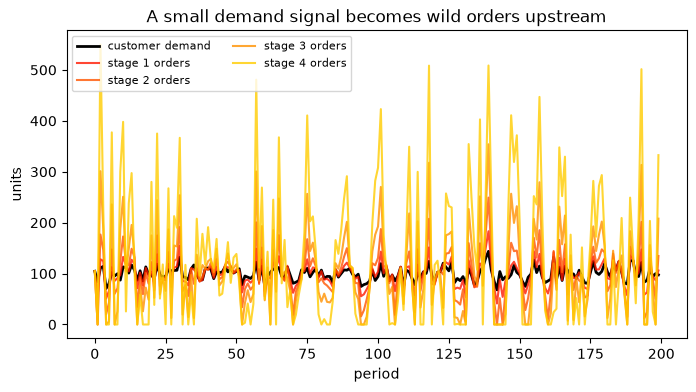

In [2]:
customer_demand = stationary_demand(bw.n_periods, mean=100.0, std=15.0, seed=SETTINGS.seed)
result = simulate_bullwhip(customer_demand, bw.n_stages, bw.forecast_window, bw.lead_time, warmup=30)
save_json({"n_stages": bw.n_stages, "forecast_window": bw.forecast_window, "lead_time": bw.lead_time,
           "customer_mean": 100.0, "customer_std": 15.0}, "06_inputs")
save_json({"variances": result.variances, "amplification": result.amplification}, "06_amplification")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(customer_demand, color="black", linewidth=2, label="customer demand")
colors = plt.cm.autumn(np.linspace(0.1, 0.8, bw.n_stages))
for stage, orders in enumerate(result.orders_by_stage):
    ax.plot(orders, color=colors[stage], alpha=0.8, label=f"stage {stage + 1} orders")
ax.set_xlabel("period")
ax.set_ylabel("units")
ax.set_title("A small demand signal becomes wild orders upstream")
ax.legend(fontsize=8, ncol=2)
save_figure(fig, "06_order_series")
plt.show()

## Order variance amplifies stage by stage

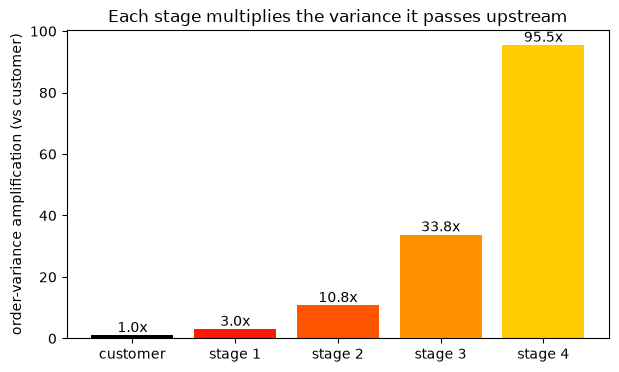

 customer:  1.00x
  stage 1:  3.01x
  stage 2: 10.76x
  stage 3: 33.76x
  stage 4: 95.47x


In [3]:
labels = ["customer", *[f"stage {i + 1}" for i in range(bw.n_stages)]]
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(labels, result.amplification, color=["black"] + list(plt.cm.autumn(np.linspace(0.1, 0.8, bw.n_stages))))
ax.bar_label(bars, fmt="%.1fx")
ax.set_ylabel("order-variance amplification (vs customer)")
ax.set_title("Each stage multiplies the variance it passes upstream")
save_figure(fig, "06_amplification_by_stage")
plt.show()
for label, amp in zip(labels, result.amplification):
    print(f"{label:>9}: {amp:5.2f}x")

## What drives the whip

Per-stage amplification rises with the replenishment **lead time** and falls with a
longer **forecast window** (more smoothing). These are the levers — alongside sharing
true demand — that damp the effect.

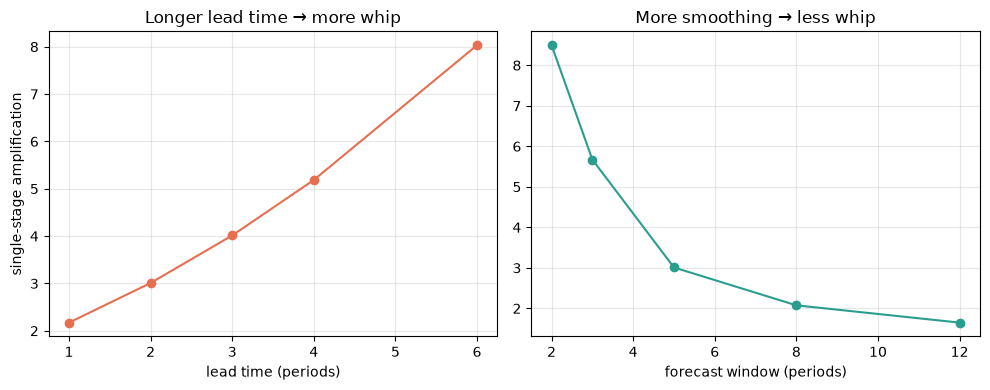

In [4]:
def single_stage_amp(forecast_window, lead_time):
    return simulate_bullwhip(customer_demand, 1, forecast_window, lead_time, warmup=30).amplification[-1]

lead_times = [1, 2, 3, 4, 6]
windows = [2, 3, 5, 8, 12]
amp_vs_lead = [single_stage_amp(5, lt) for lt in lead_times]
amp_vs_window = [single_stage_amp(fw, 2) for fw in windows]
save_json({"lead_times": lead_times, "amp_vs_lead_time": amp_vs_lead,
           "forecast_windows": windows, "amp_vs_forecast_window": amp_vs_window}, "06_drivers")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(lead_times, amp_vs_lead, marker="o", color="#e76f51")
axes[0].set_xlabel("lead time (periods)")
axes[0].set_ylabel("single-stage amplification")
axes[0].set_title("Longer lead time → more whip")
axes[0].grid(alpha=0.3)
axes[1].plot(windows, amp_vs_window, marker="o", color="#2a9d8f")
axes[1].set_xlabel("forecast window (periods)")
axes[1].set_title("More smoothing → less whip")
axes[1].grid(alpha=0.3)
fig.tight_layout()
save_figure(fig, "06_amplification_drivers")
plt.show()

## The decision framework

The supply chain that felt like a series of judgment calls is a stack of optimization
problems, each with an exact answer:

| Decision | Model | The guess it replaces |
|---|---|---|
| How much to stock for a season | **Newsvendor** — critical-ratio quantile | stock to the mean |
| How much / when to reorder | **EOQ** and **(s, S) / (R, Q)** policies | round-number rules |
| How big a buffer | **Service-level safety stock** from σ, L, target | flat "N weeks" |
| Where to put warehouses | **Facility-location MILP** (+ shadow prices) | nearest-site map-reading |
| How to route product | **Transportation / transshipment LP** | manual lanes |
| Where to hold stock | **Multi-echelon / risk pooling** | a buffer everywhere |
| Coordinating the chain | **Global view** (damp the bullwhip) | local optimization |

The forecast is the **input**; the decision it feeds is the **value**, and every
decision is an optimization problem with an exact, better-than-the-guess answer.

In [5]:
takeaways = {
    "thesis": "Local order reactions amplify demand variance upstream; the chain needs a global view.",
    "n_stages": bw.n_stages,
    "top_stage_amplification": round(result.amplification[-1], 2),
    "amplification_by_stage": [round(a, 2) for a in result.amplification],
    "driver_lead_time": "longer lead time increases amplification",
    "driver_forecast_window": "more smoothing decreases amplification",
}
save_json(takeaways, "06_takeaways")
takeaways

{'thesis': 'Local order reactions amplify demand variance upstream; the chain needs a global view.',
 'n_stages': 4,
 'top_stage_amplification': 95.47,
 'amplification_by_stage': [1.0, 3.01, 10.76, 33.76, 95.47],
 'driver_lead_time': 'longer lead time increases amplification',
 'driver_forecast_window': 'more smoothing decreases amplification'}